# The version timeline: v1 min-max → v4 deployed

## Goal

Put the four versions of the engine head to head, exactly as docs/EVALUATION.md, section 11
reports it:

- **v1 — naive min-max**, hand-tuned weights (the documented baseline);
- **v2 — alpha-beta**, same weights: pure algorithmic speed, provably identical play;
- **v3 — alpha-beta + tuned weights**: the GA champion in place of the hand-tuned set;
- **v4 — the deployed engine**: tuned weights plus quiescence, forward pruning and the
  opening book.

Two questions, both at the deployment depth 3: **who wins** — every adjacent pairing of the
timeline plus the full journey v1-vs-v4, one deterministic game per color assignment through
the section-9 protocol (center opening, 60-ply cap, weights installed per search) — and
**what it costs** — the section-10 positions plus the opening reply, where the book answers
instead of a search, at depths 3 and 4.

The engines are deterministic, so every game outcome, ply count, node count and score below
reproduces docs/EVALUATION.md, sections 11.1 and 11.2 exactly; only wall times vary. The
validation cells assert all of it — a clean run of this notebook is a validation of the
section-11 tables.

## Expected behaviour

The ladder must hold: v1 and v2 split their pairing (alpha-beta changes the price of a move,
never the move — both games are the section-9 baseline mirror at ply 38); v3 beats v2 in
both colors (plies 17 and 36, the section-9 champion head-to-head); v4 beats v3 and v1 in
both colors; and no version ever loses to an earlier one.

Runtime: about 7 minutes (the two v1 games dominate).

In [1]:
import os
import sys
import time
from dataclasses import dataclass
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tuning" / "default.json").is_file())
os.environ["WEIGHTS_FILE"] = str(ROOT / "tuning" / "default.json")
sys.path.insert(0, str(ROOT / "tuning"))

import genetic_tuner as gt
import harness
from connect6.defines import Color, SearchStats
from connect6.opening_book import book_move, load_opening_book
from connect6.protocol import move2msg
from connect6.search import search_alpha_beta, search_alpha_beta_with_quiescence, search_min_max

DEPTH = 3
MAX_PLIES = 60


@dataclass(frozen=True, slots=True)
class Version:
    name: str
    weights: gt.Weights
    search: str
    use_book: bool


champion = harness.load_weights(ROOT / "tuning" / "winner.json")
VERSIONS = [
    Version("v1 min-max", gt.BASE, "min_max", False),
    Version("v2 alpha-beta", gt.BASE, "alpha_beta", False),
    Version("v3 alpha-beta + tuned weights", champion, "alpha_beta", False),
    Version("v4 + quiescence, pruning, book", champion, "enhanced", True),
]
SEARCHES = {
    "min_max": search_min_max,
    "alpha_beta": search_alpha_beta,
    "enhanced": search_alpha_beta_with_quiescence,
}
BOOK = load_opening_book()

print(f"weights pinned to {os.environ['WEIGHTS_FILE']} (installed per search by the referee)")
for version in VERSIONS:
    print(f"  {version.name}: {gt.fmt(version.weights)}")

weights pinned to /Users/e.butovka/Documents/MyProjects/Connect6Engine/tuning/default.json (installed per search by the referee)
  v1 min-max: tiers=(1, 10, 100, 1000, 10000) factor=(2, 3) threat=1000
  v2 alpha-beta: tiers=(1, 10, 100, 1000, 10000) factor=(2, 3) threat=1000
  v3 alpha-beta + tuned weights: tiers=(1, 18, 93, 716, 10000) factor=(1, 3) threat=1724
  v4 + quiescence, pruning, book: tiers=(1, 18, 93, 716, 10000) factor=(1, 3) threat=1724


## Who is winning

Every game is one deterministic pairing; the v4 player consults the opening book before
searching, installs its weights per search through the genetic tuner's own `apply_weights`,
and both sides share the referee from `tuning/harness.py`. The `book hits` extras count the
moves answered without a search.

In [2]:
def think(version, board, color, depth, pre_move, stats):
    if version.use_book:
        booked = book_move(board, BOOK)
        if booked is not None:
            return booked, None
    gt.apply_weights(version.weights)
    result = SEARCHES[version.search](board, color, depth, pre_move, stats)
    return result.move, result.score


def timed_think(version, board, color, depth, pre_move, tally):
    stats = SearchStats()
    start = time.perf_counter()
    move, score = think(version, board, color, depth, pre_move, stats)
    tally.ms += (time.perf_counter() - start) * 1000
    tally.nodes += stats.node_count
    tally.moves += 1
    if version.use_book and stats.node_count == 0:
        tally.book_hits += 1
    return move, score


def make_player(version):
    def player(board, color, depth, pre_move, stats):
        move, _ = think(version, board, color, depth, pre_move, stats)
        return move

    return player


game_rows = []
pairings = [(0, 1), (1, 2), (2, 3), (0, 3)]
print("== games: adjacent steps of the timeline, plus the full journey ==")
for left, right in pairings:
    for black_first in (True, False):
        black_version = VERSIONS[left] if black_first else VERSIONS[right]
        white_version = VERSIONS[right] if black_first else VERSIONS[left]
        start = time.perf_counter()
        record = harness.play_game(make_player(black_version), make_player(white_version), DEPTH, MAX_PLIES)
        elapsed = time.perf_counter() - start
        if record.winner is None:
            outcome, who = "draw", "nobody"
        else:
            outcome = f"{'black' if record.winner is Color.BLACK else 'white'} wins"
            who = black_version.name if record.winner is Color.BLACK else white_version.name
        extras = []
        if record.black.book_hits:
            extras.append(f"black book hits {record.black.book_hits}")
        if record.white.book_hits:
            extras.append(f"white book hits {record.white.book_hits}")
        print(
            f"{black_version.name} (black) vs {white_version.name} (white): "
            f"{outcome} — {who}, ply {record.plies}, {elapsed:.0f} s | "
            f"black: {record.black.moves} moves, {record.black.nodes} nodes, {record.black.ms / max(record.black.moves, 1):.0f} ms/move | "
            f"white: {record.white.moves} moves, {record.white.nodes} nodes, {record.white.ms / max(record.white.moves, 1):.0f} ms/move"
            + (" | " + ", ".join(extras) if extras else "")
        )
        game_rows.append((black_version.name, white_version.name, outcome, who, record.plies,
                          record.black.book_hits, record.white.book_hits))
print()

== games: adjacent steps of the timeline, plus the full journey ==


v1 min-max (black) vs v2 alpha-beta (white): black wins — v1 min-max, ply 38, 65 s | black: 19 moves, 523459 nodes, 3161 ms/move | white: 19 moves, 36379 nodes, 271 ms/move


v2 alpha-beta (black) vs v1 min-max (white): black wins — v2 alpha-beta, ply 38, 64 s | black: 19 moves, 29266 nodes, 227 ms/move | white: 19 moves, 526489 nodes, 3151 ms/move


v2 alpha-beta (black) vs v3 alpha-beta + tuned weights (white): white wins — v3 alpha-beta + tuned weights, ply 17, 3 s | black: 8 moves, 14559 nodes, 198 ms/move | white: 9 moves, 16675 nodes, 194 ms/move


v3 alpha-beta + tuned weights (black) vs v2 alpha-beta (white): black wins — v3 alpha-beta + tuned weights, ply 36, 8 s | black: 18 moves, 31116 nodes, 246 ms/move | white: 18 moves, 29910 nodes, 215 ms/move


v3 alpha-beta + tuned weights (black) vs v4 + quiescence, pruning, book (white): white wins — v4 + quiescence, pruning, book, ply 19, 8 s | black: 9 moves, 16562 nodes, 209 ms/move | white: 10 moves, 18297 nodes, 615 ms/move | white book hits 1


v4 + quiescence, pruning, book (black) vs v3 alpha-beta + tuned weights (white): black wins — v4 + quiescence, pruning, book, ply 26, 33 s | black: 13 moves, 74624 nodes, 2294 ms/move | white: 13 moves, 28517 nodes, 266 ms/move


v1 min-max (black) vs v4 + quiescence, pruning, book (white): white wins — v4 + quiescence, pruning, book, ply 19, 27 s | black: 9 moves, 249099 nodes, 2346 ms/move | white: 10 moves, 18297 nodes, 620 ms/move | white book hits 1


v4 + quiescence, pruning, book (black) vs v1 min-max (white): black wins — v4 + quiescence, pruning, book, ply 26, 65 s | black: 13 moves, 74624 nodes, 2339 ms/move | white: 13 moves, 360943 nodes, 2646 ms/move



## Validation

The cell below re-checks every game against the documented table — outcome, winner, ply —
plus the book-hit pattern: exactly one book hit per v4-as-white game (the opening reply),
none anywhere else.

In [3]:
EXPECTED_GAMES = [
    ("v1 min-max", "v2 alpha-beta", "black wins", "v1 min-max", 38),
    ("v2 alpha-beta", "v1 min-max", "black wins", "v2 alpha-beta", 38),
    ("v2 alpha-beta", "v3 alpha-beta + tuned weights", "white wins", "v3 alpha-beta + tuned weights", 17),
    ("v3 alpha-beta + tuned weights", "v2 alpha-beta", "black wins", "v3 alpha-beta + tuned weights", 36),
    ("v3 alpha-beta + tuned weights", "v4 + quiescence, pruning, book", "white wins", "v4 + quiescence, pruning, book", 19),
    ("v4 + quiescence, pruning, book", "v3 alpha-beta + tuned weights", "black wins", "v4 + quiescence, pruning, book", 26),
    ("v1 min-max", "v4 + quiescence, pruning, book", "white wins", "v4 + quiescence, pruning, book", 19),
    ("v4 + quiescence, pruning, book", "v1 min-max", "black wins", "v4 + quiescence, pruning, book", 26),
]

for expected, row in zip(EXPECTED_GAMES, game_rows):
    measured = row[:5]
    assert measured == expected, f"measured {measured}, documented {expected}"
v4_white = [row for row in game_rows if row[1] == "v4 + quiescence, pruning, book"]
assert len(v4_white) == 2 and all(row[6] == 1 for row in v4_white)
assert all(row[5] == 0 for row in game_rows)
print("all 8 games reproduce section 11.1 exactly (outcome, winner, ply, one book hit per v4-white game)")

all 8 games reproduce section 11.1 exactly (outcome, winner, ply, one book hit per v4-white game)


## What it costs

One search per position per version, deterministic. `book` marks the position the opening
book answered without a search — the whole v4 book story in one row: the opening reply that
costs v3 2,918 nodes at depth 3 (and 25,469 at depth 4) costs v4 nothing. The min-max rows
at depth 4 are omitted: those trees are minutes long, and the depth-3 rows already make the
point (27,931 nodes whatever the position — the naive search is position-blind).

In [4]:
cost_rows = {}
positions = harness.documented_positions()
for depth in (DEPTH, DEPTH + 1):
    rows = [v for v in VERSIONS if depth == DEPTH or v.search != "min_max"]
    note = "" if len(rows) == len(VERSIONS) else " (min-max omitted: the naive depth-4 trees are minutes long)"
    print(f"== timing and nodes at depth {depth}{note} ==")
    print(f"{'position':34s} {'version':38s} {'nodes':>7s} {'ms':>8s} {'score':>7s}  move")
    for label, board, color, pre_move in positions:
        for version in rows:
            tally = harness.Tally()
            move, score = timed_think(version, board, color, depth, pre_move, tally)
            booked = version.use_book and score is None
            print(
                f"{label:34s} {version.name:38s} {tally.nodes:7d} {tally.ms:8.1f} "
                f"{'book' if booked else str(score):>7}  {move2msg(move)}{'  (book)' if booked else ''}"
            )
            cost_rows[(depth, label, version.name)] = (tally.nodes, score, move2msg(move))
    print()

== timing and nodes at depth 3 ==
position                           version                                  nodes       ms   score  move


opening reply, white to move       v1 min-max                               27931   1428.3    -303  IJJK


opening reply, white to move       v2 alpha-beta                             2830    216.9    -303  IJJK
opening reply, white to move       v3 alpha-beta + tuned weights             2918    220.7    -282  IJJK
opening reply, white to move       v4 + quiescence, pruning, book               0      0.0    book  IIKK  (book)


opening scatter, white to move     v1 min-max                               27931   1829.2    -510  KQCK
opening scatter, white to move     v2 alpha-beta                             1182    118.1    -510  KQCK


opening scatter, white to move     v3 alpha-beta + tuned weights             1593    145.4    -436  CIIP


...

midgame, white to move             v3 alpha-beta + tuned weights            11799   2011.5    -305  FJKI


midgame, white to move             v4 + quiescence, pruning, book            3782   1561.7    -617  JGII
fork attack, black to move         v2 alpha-beta                              350     45.5   20000  JNBJ
fork attack, black to move         v3 alpha-beta + tuned weights              347     45.7   20000  JNBJ
fork attack, black to move         v4 + quiescence, pruning, book             179     66.1   20000  JNBJ


fork completed, white to move      v2 alpha-beta                              577    181.5   20000  GJHJ
fork completed, white to move      v3 alpha-beta + tuned weights              573    186.1   20000  GJHJ


fork completed, white to move      v4 + quiescence, pruning, book             349    113.8   20000  GJHJ
five-run attack, white to move     v2 alpha-beta                             1616    191.8   11613  HJBJ


five-run attack, white to move     v3 alpha-beta + tuned weights             1616    191.7   11596  HJBJ
five-run attack, white to move     v4 + quiescence, pruning, book             110     30.7   20000  HJBJ



In [5]:
EXPECTED_COST = {
    (3, "opening reply, white to move", "v1 min-max"): (27931, -303, "IJJK"),
    (3, "opening reply, white to move", "v2 alpha-beta"): (2830, -303, "IJJK"),
    (3, "opening reply, white to move", "v3 alpha-beta + tuned weights"): (2918, -282, "IJJK"),
    (3, "opening reply, white to move", "v4 + quiescence, pruning, book"): (0, None, "IIKK"),
    (3, "opening scatter, white to move", "v1 min-max"): (27931, -510, "KQCK"),
    (3, "opening scatter, white to move", "v2 alpha-beta"): (1182, -510, "KQCK"),
    (3, "opening scatter, white to move", "v3 alpha-beta + tuned weights"): (1593, -436, "CIIP"),
    (3, "opening scatter, white to move", "v4 + quiescence, pruning, book"): (1668, -386, "CKJP"),
    (3, "midgame, white to move", "v1 min-max"): (27931, -3097, "FJII"),
    (3, "midgame, white to move", "v2 alpha-beta"): (1390, -3097, "FJII"),
    (3, "midgame, white to move", "v3 alpha-beta + tuned weights"): (1425, -2342, "FJII"),
    (3, "midgame, white to move", "v4 + quiescence, pruning, book"): (1458, -703, "BJII"),
    (3, "fork attack, black to move", "v1 min-max"): (27931, 20000, "JNBJ"),
    (3, "fork attack, black to move", "v2 alpha-beta"): (78, 20000, "JNBJ"),
    (3, "fork attack, black to move", "v3 alpha-beta + tuned weights"): (78, 20000, "JNBJ"),
    (3, "fork attack, black to move", "v4 + quiescence, pruning, book"): (78, 20000, "JNBJ"),
    (3, "fork completed, white to move", "v1 min-max"): (24631, 20000, "GJHJ"),
    (3, "fork completed, white to move", "v2 alpha-beta"): (351, 20000, "GJHJ"),
    (3, "fork completed, white to move", "v3 alpha-beta + tuned weights"): (347, 20000, "GJHJ"),
    (3, "fork completed, white to move", "v4 + quiescence, pruning, book"): (207, 20000, "GJHJ"),
    (3, "five-run attack, white to move", "v1 min-max"): (14461, 1577, "HJBJ"),
    (3, "five-run attack, white to move", "v2 alpha-beta"): (249, 1577, "HJBJ"),
    (3, "five-run attack, white to move", "v3 alpha-beta + tuned weights"): (249, 1536, "HJBJ"),
    (3, "five-run attack, white to move", "v4 + quiescence, pruning, book"): (103, 20000, "HJBJ"),
    (4, "opening reply, white to move", "v2 alpha-beta"): (24533, 303, "IJJK"),
    (4, "opening reply, white to move", "v3 alpha-beta + tuned weights"): (25469, 282, "IJJK"),
    (4, "opening reply, white to move", "v4 + quiescence, pruning, book"): (0, None, "IIKK"),
    (4, "opening scatter, white to move", "v2 alpha-beta"): (9150, -66, "KQCK"),
    (4, "opening scatter, white to move", "v3 alpha-beta + tuned weights"): (15964, -40, "CKJP"),
    (4, "opening scatter, white to move", "v4 + quiescence, pruning, book"): (7581, -38, "CKJP"),
    (4, "midgame, white to move", "v2 alpha-beta"): (11640, -301, "FJKI"),
    (4, "midgame, white to move", "v3 alpha-beta + tuned weights"): (11799, -305, "FJKI"),
    (4, "midgame, white to move", "v4 + quiescence, pruning, book"): (3782, -617, "JGII"),
    (4, "fork attack, black to move", "v2 alpha-beta"): (350, 20000, "JNBJ"),
    (4, "fork attack, black to move", "v3 alpha-beta + tuned weights"): (347, 20000, "JNBJ"),
    (4, "fork attack, black to move", "v4 + quiescence, pruning, book"): (179, 20000, "JNBJ"),
    (4, "fork completed, white to move", "v2 alpha-beta"): (577, 20000, "GJHJ"),
    (4, "fork completed, white to move", "v3 alpha-beta + tuned weights"): (573, 20000, "GJHJ"),
    (4, "fork completed, white to move", "v4 + quiescence, pruning, book"): (349, 20000, "GJHJ"),
    (4, "five-run attack, white to move", "v2 alpha-beta"): (1616, 11613, "HJBJ"),
    (4, "five-run attack, white to move", "v3 alpha-beta + tuned weights"): (1616, 11596, "HJBJ"),
    (4, "five-run attack, white to move", "v4 + quiescence, pruning, book"): (110, 20000, "HJBJ"),
}

for key, expected in EXPECTED_COST.items():
    measured = cost_rows[key]
    assert measured == expected, f"{key}: measured {measured}, documented {expected}"
print(f"all {len(EXPECTED_COST)} cost rows reproduce section 11.2 exactly (nodes, score, move)")

all 42 cost rows reproduce section 11.2 exactly (nodes, score, move)


## Charts

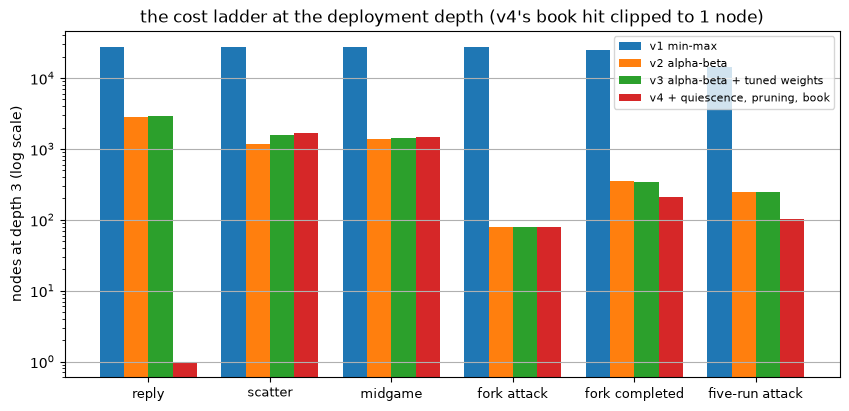

In [6]:
import matplotlib.pyplot as plt

labels = [label for label, *_ in positions]
short = [label.split(",")[0].replace("opening ", "") for label in labels]
width = 0.2
fig, ax = plt.subplots(figsize=(10, 4.5))
for i, version in enumerate(VERSIONS):
    nodes = [max(cost_rows[(3, label, version.name)][0], 1) for label in labels]
    ax.bar([j + (i - 1.5) * width for j in range(len(labels))], nodes, width, label=version.name)
ax.set_yscale("log")
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(short, fontsize=9)
ax.set_ylabel("nodes at depth 3 (log scale)")
ax.set_title("the cost ladder at the deployment depth (v4's book hit clipped to 1 node)")
ax.grid(True, axis="y")
ax.legend(fontsize=8)
plt.show()

## Reading the results

- **v1 and v2 are the same player** — identical moves, ply 38, black wins both games of the
  pairing: the section-9 baseline mirror, reproduced.
- **Weights alone win games** — v3 beats v2 in both colors; **the enhancements carry it to
  full games** — v4 beats v3 in both colors.
- **v4's games against v1 are move-for-move identical to its games against v3** — once v4's
  forcing lines take over, the opponent's weights stop changing its choices: section 9.3's
  weight-invariance, observed from the other side.
- Full discussion: docs/EVALUATION.md, sections 11.3 and 11.4.